Thanks Claude

# READ ME FIRST

- To toggle percentage or raw count plotting in the baseline / policy / reward function comparison plots, go to the cell defining USE_PERCENTAGES and set to True or False as desired.
- You should be able to change / add new plots just by changing the input files. This is vibecoded though, so can't make strong promises.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re

## Load data

In [2]:
DATA_DIR = "data"

In [3]:
def load_run(path):
    df = pd.read_csv(path)
    # "categories Pornography" -> "Pornography"
    df["category"] = df["action"].str.replace("categories ", "", regex=False)
    return df.sort_values(["episode", "time"]).reset_index(drop=True)

In [128]:
name_map = {
    "baseline": "Baseline",
    "exp1": "Naive UCB",
    "exp2": "LinUCB Shared",
    "exp3": "LinUCB",
    "exp4": "ClusterLinUCB",
    "exp5": "UCB, maj. vote",
    "exp6": "UCB, partial (VPs)",
    "exp7": "UCB, partial (ASNs)",
}

color_map = {
    "baseline": "green",
    "exp1": "red",
    "exp2": "purple",
    "exp3": "cyan",
    "exp4": "orange",
    "exp5": "red",
    "exp6": "red",
    "exp7": "red",
}

line_map = {
    "baseline": "solid",
    "exp1": "solid",
    "exp2": "solid",
    "exp3": "solid",
    "exp4": "solid",
    "exp5": "dotted",
    "exp6": "solid",
    "exp7": "dashed",
}

def get_experiment_name(path):
    exp_num = None
    if "baseline" in path:
        exp_num = "baseline"
    else:
        exp_num = re.search(r"exp\d", path).group(0)
    return name_map[exp_num]

def get_experiment_color(path):
    exp_num = None
    if "baseline" in path:
        exp_num = "baseline"
    else:
        exp_num = re.search(r"exp\d", path).group(0)
    return color_map[exp_num]

def get_experiment_linestyle(path):
    exp_num = None
    if "baseline" in path:
        exp_num = "baseline"
    else:
        exp_num = re.search(r"exp\d", path).group(0)
    return line_map[exp_num]
    

## Over-time comparisons (vs baseline, vs other policies, vs other rewards)

In [112]:
USE_PERCENTAGES = False

In [68]:
def get_times(df):
    return df["time"]

In [69]:
def cumulative_found(df):
    # each blocked measurement is a new censored domain (targets are unique)
    return df["is_blocked"].cumsum().to_numpy()

In [70]:
def convert_to_percentage(run):
    return 100 * (run / run[-1]) if run[-1] > 0 else run

In [71]:
def get_over_time_compare_data(files):
    runs = list(map(load_run, files))
    times = list(map(lambda df: df["time"], runs))
    names = list(map(get_experiment_name, files))
    colors = list(map(get_experiment_color, files))
    linestyles = list(map(get_experiment_linestyle, files))

    if USE_PERCENTAGES:
        runs = list(map(convert_to_percentage, map(cumulative_found, runs)))
    else:
        runs = list(map(cumulative_found, runs))

    return runs, times, names, colors, linestyles

In [72]:
files = [
    f"{DATA_DIR}/exp1/Iran.csv",
    f"{DATA_DIR}/baseline/Iran.csv"
]

get_over_time_compare_data(files) 


([array([  1,   2,   3, ..., 864, 864, 864], shape=(2000,)),
  array([  0,   0,   1, ..., 383, 384, 384], shape=(2000,))],
 [0          1
  1          2
  2          3
  3          4
  4          5
          ... 
  1995    1996
  1996    1997
  1997    1998
  1998    1999
  1999    2000
  Name: time, Length: 2000, dtype: int64,
  0          1
  1          2
  2          3
  3          4
  4          5
          ... 
  1995    1996
  1996    1997
  1997    1998
  1998    1999
  1999    2000
  Name: time, Length: 2000, dtype: int64],
 ['Naive UCB', 'Baseline'],
 ['red', 'green'],
 ['solid', 'solid'])

### vs baseline

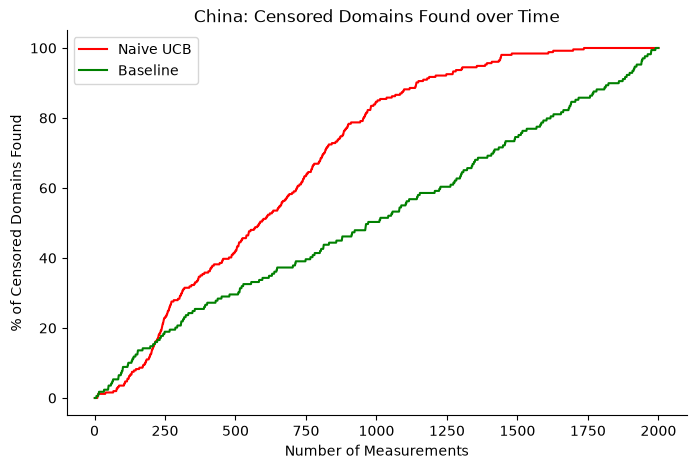

In [94]:
files = [
    f"{DATA_DIR}/exp1/China.csv",
    f"{DATA_DIR}/baseline/China.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("China: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

2


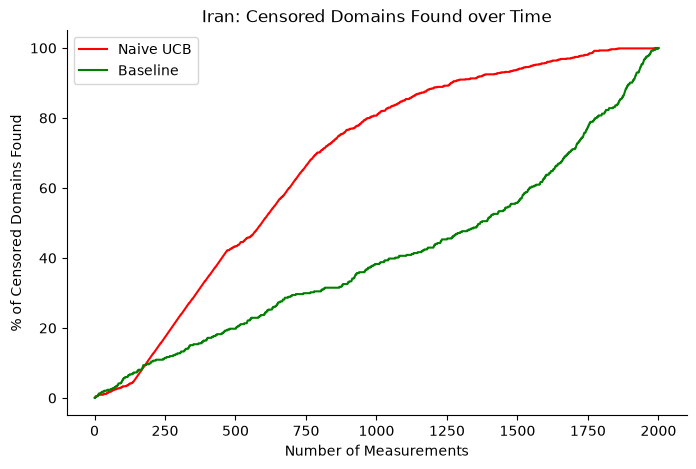

In [95]:
files = [
    f"{DATA_DIR}/exp1/Iran.csv",
    f"{DATA_DIR}/baseline/Iran.csv"
]

runs, times, names, colors, lines = get_over_time_compare_data(files) 
print(len(runs))
# = list(map(load_run, files)
# times = list(map(lambda df: df["time"], runs))
# names = list(map(get_exeriment_name, files))

# runs = list(map(convert_to_percentage, map(cumulative_found, runs)))

# # Denominator: all censored domains found by EITHER run, so both curves
# # share one scale. Change this line if you want a different definition.
# total_censored = max(exp_found[-1], base_found[-1])

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

# ax.plot(exp["time"], 100 * exp_found / total_censored, label="exp6")
# ax.plot(base["time"], 100 * base_found / total_censored, label="baseline")
# ax.plot(exp["time"], 100 * exp_found / exp_found[-1], label="exp6")
# ax.plot(base["time"], 100 * base_found / base_found[-1], label="baseline")
ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Iran: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

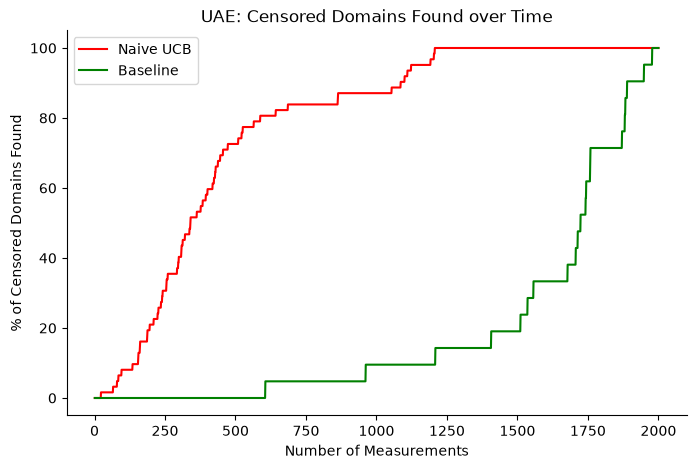

In [96]:
files = [
    f"{DATA_DIR}/exp1/United_Arab_Emirates.csv",
    f"{DATA_DIR}/baseline/United_Arab_Emirates.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("UAE: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

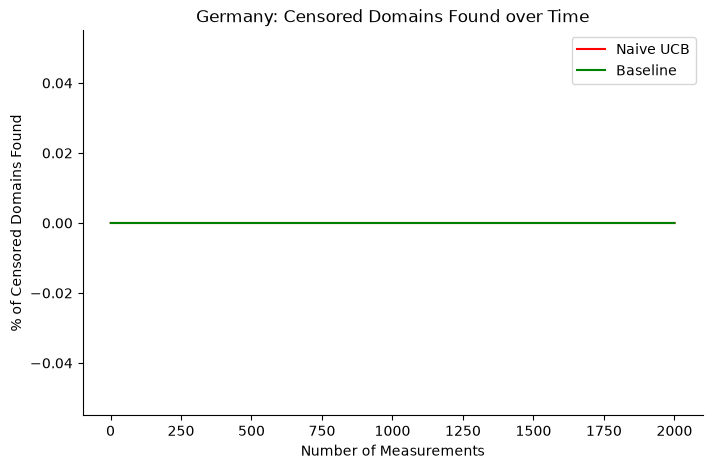

In [97]:
files = [
    f"{DATA_DIR}/exp1/Germany.csv",
    f"{DATA_DIR}/baseline/Germany.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Germany: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

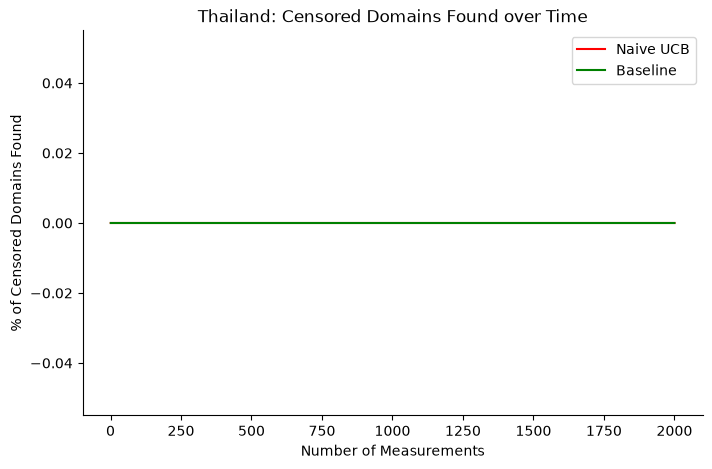

In [98]:
files = [
    f"{DATA_DIR}/exp1/Thailand.csv",
    f"{DATA_DIR}/baseline/Thailand.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Thailand: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

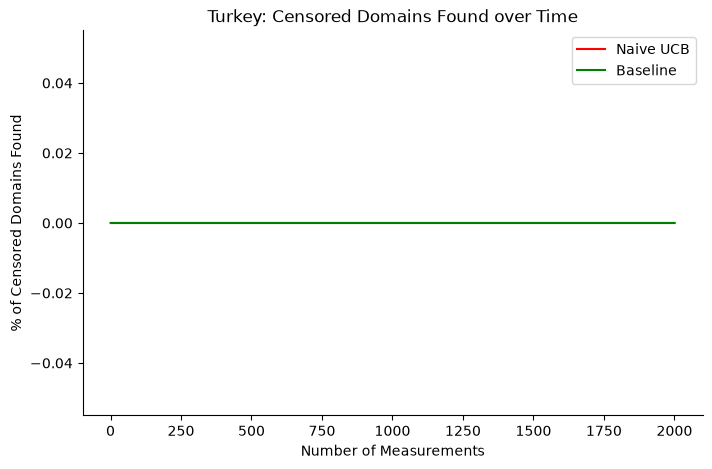

In [99]:
files = [
    f"{DATA_DIR}/exp1/Turkey.csv",
    f"{DATA_DIR}/baseline/Turkey.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Turkey: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

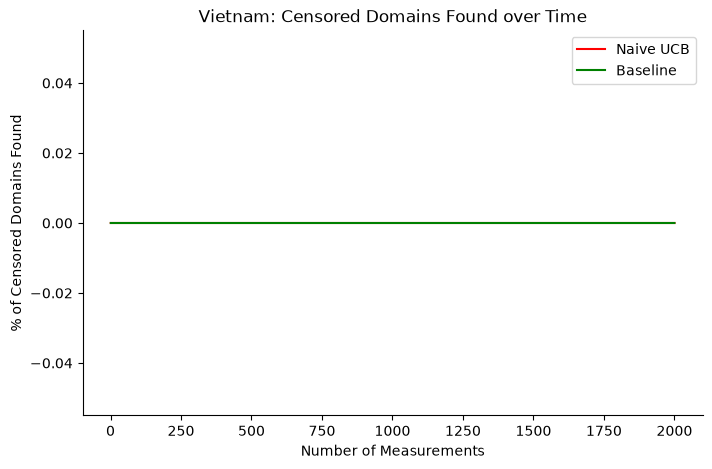

In [100]:
files = [
    f"{DATA_DIR}/exp1/Vietnam.csv",
    f"{DATA_DIR}/baseline/Vietnam.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Vietnam: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

### Policy comparison

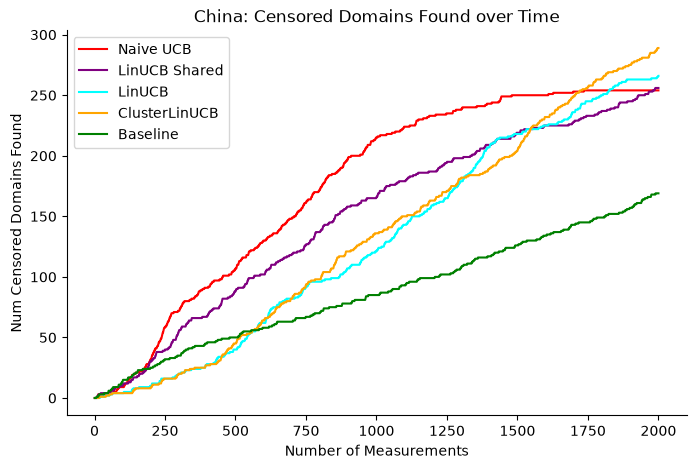

In [113]:
files = [
    f"{DATA_DIR}/exp1/China.csv",
    f"{DATA_DIR}/exp2/China.csv",
    f"{DATA_DIR}/exp3/China.csv",
    f"{DATA_DIR}/exp4/China.csv",
    f"{DATA_DIR}/baseline/China.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("China: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

5


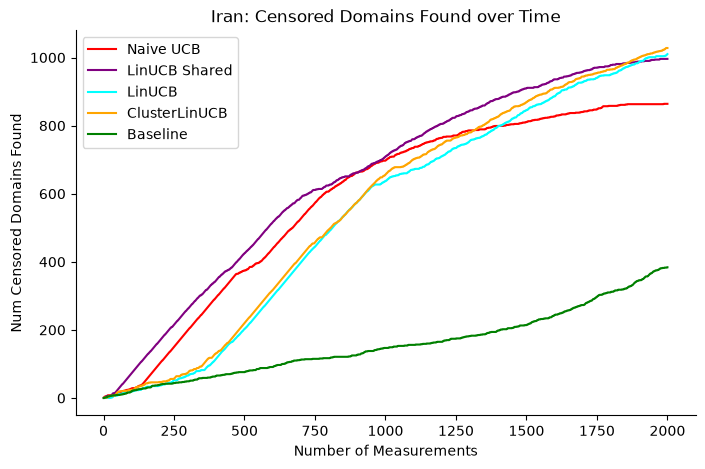

In [114]:
files = [
    f"{DATA_DIR}/exp1/Iran.csv",
    f"{DATA_DIR}/exp2/Iran.csv",
    f"{DATA_DIR}/exp3/Iran.csv",
    f"{DATA_DIR}/exp4/Iran.csv",
    f"{DATA_DIR}/baseline/Iran.csv"
]

runs, times, names, colors, lines = get_over_time_compare_data(files) 
print(len(runs))
# = list(map(load_run, files)
# times = list(map(lambda df: df["time"], runs))
# names = list(map(get_exeriment_name, files))

# runs = list(map(convert_to_percentage, map(cumulative_found, runs)))

# # Denominator: all censored domains found by EITHER run, so both curves
# # share one scale. Change this line if you want a different definition.
# total_censored = max(exp_found[-1], base_found[-1])

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

# ax.plot(exp["time"], 100 * exp_found / total_censored, label="exp6")
# ax.plot(base["time"], 100 * base_found / total_censored, label="baseline")
# ax.plot(exp["time"], 100 * exp_found / exp_found[-1], label="exp6")
# ax.plot(base["time"], 100 * base_found / base_found[-1], label="baseline")
ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Iran: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

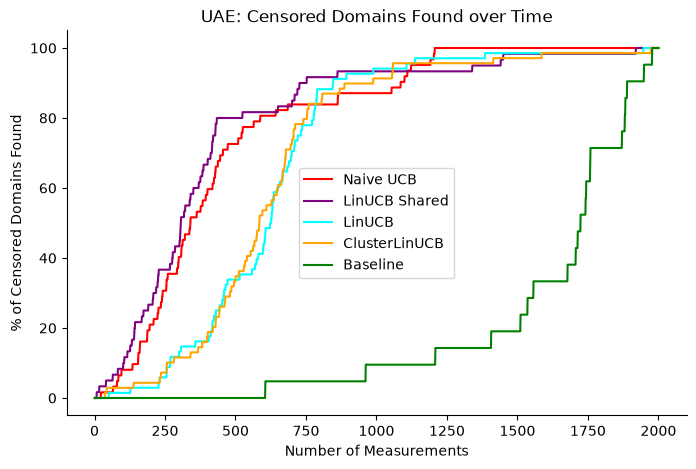

In [103]:
files = [
    f"{DATA_DIR}/exp1/United_Arab_Emirates.csv",
    f"{DATA_DIR}/exp2/United_Arab_Emirates.csv",
    f"{DATA_DIR}/exp3/United_Arab_Emirates.csv",
    f"{DATA_DIR}/exp4/United_Arab_Emirates.csv",
    f"{DATA_DIR}/baseline/United_Arab_Emirates.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("UAE: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

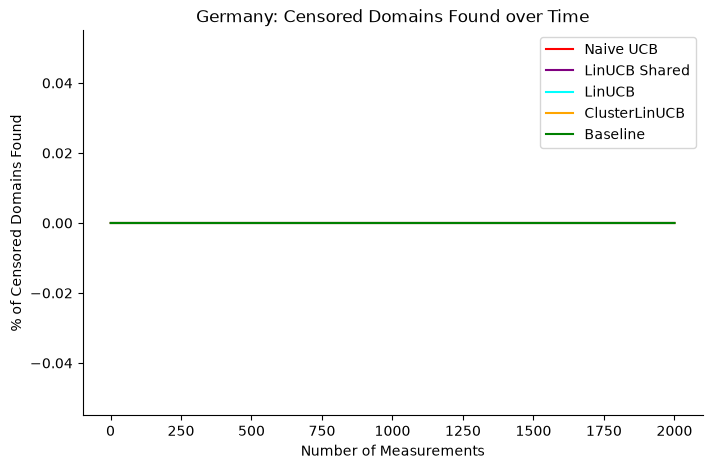

In [104]:
files = [
    f"{DATA_DIR}/exp1/Germany.csv",
    f"{DATA_DIR}/exp2/Germany.csv",
    f"{DATA_DIR}/exp3/Germany.csv",
    f"{DATA_DIR}/exp4/Germany.csv",
    f"{DATA_DIR}/baseline/Germany.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Germany: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

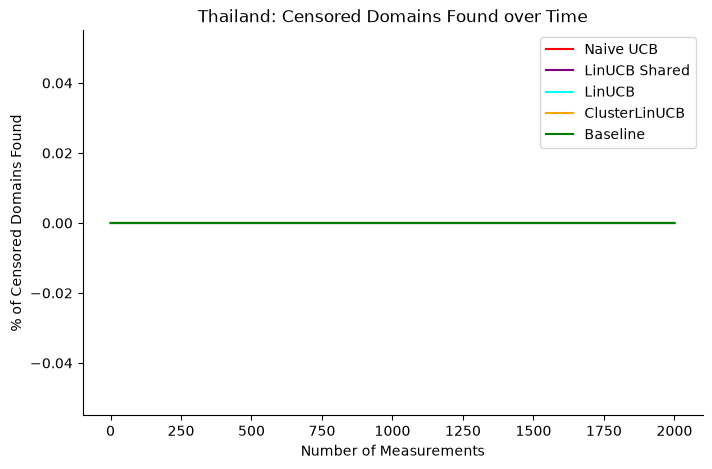

In [105]:
files = [
    f"{DATA_DIR}/exp1/Thailand.csv",
    f"{DATA_DIR}/exp2/Thailand.csv",
    f"{DATA_DIR}/exp3/Thailand.csv",
    f"{DATA_DIR}/exp4/Thailand.csv",
    f"{DATA_DIR}/baseline/Thailand.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Thailand: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

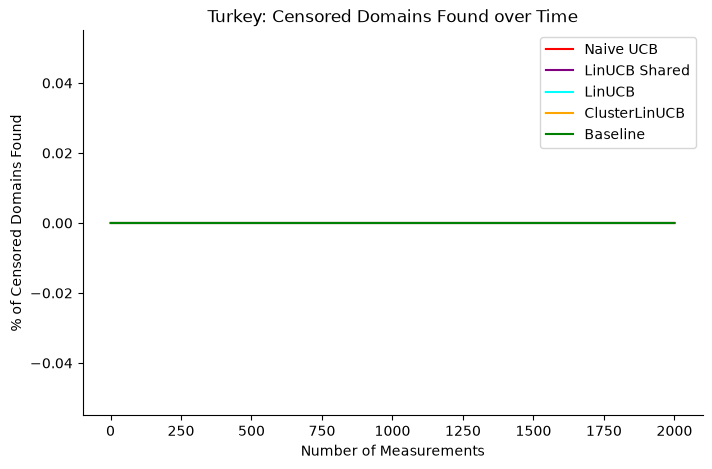

In [106]:
files = [
    f"{DATA_DIR}/exp1/Turkey.csv",
    f"{DATA_DIR}/exp2/Turkey.csv",
    f"{DATA_DIR}/exp3/Turkey.csv",
    f"{DATA_DIR}/exp4/Turkey.csv",
    f"{DATA_DIR}/baseline/Turkey.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Turkey: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

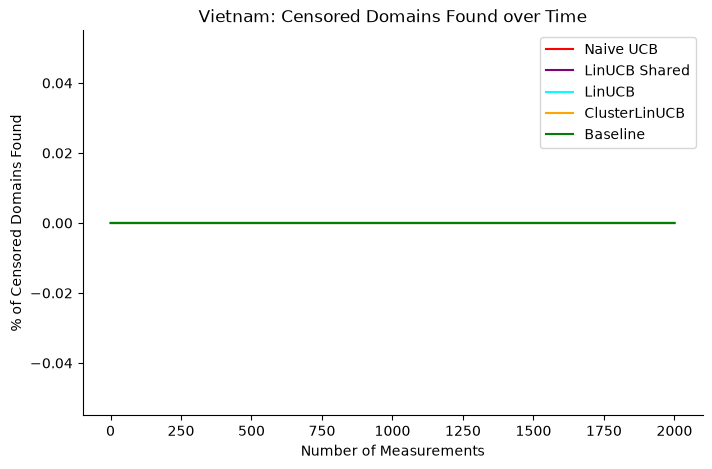

In [107]:
files = [
    f"{DATA_DIR}/exp1/Vietnam.csv",
    f"{DATA_DIR}/exp2/Vietnam.csv",
    f"{DATA_DIR}/exp3/Vietnam.csv",
    f"{DATA_DIR}/exp4/Vietnam.csv",
    f"{DATA_DIR}/baseline/Vietnam.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Vietnam: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

### Reward comparison

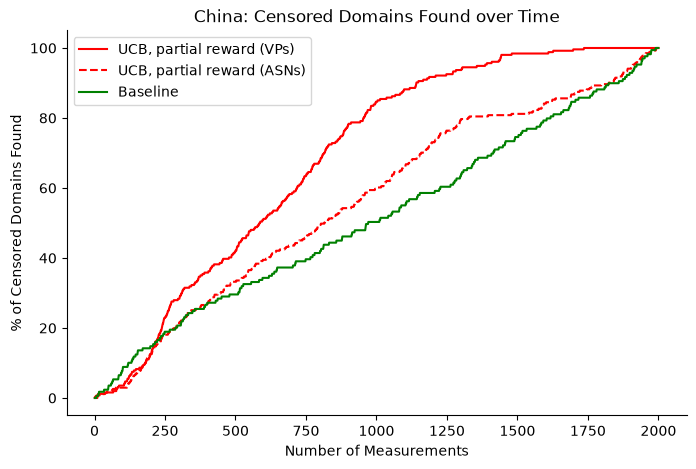

In [108]:
files = [
    # f"{DATA_DIR}/exp5/China.csv",
    f"{DATA_DIR}/exp6/China.csv",
    f"{DATA_DIR}/exp7/China.csv",
    f"{DATA_DIR}/baseline/China.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("China: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

3


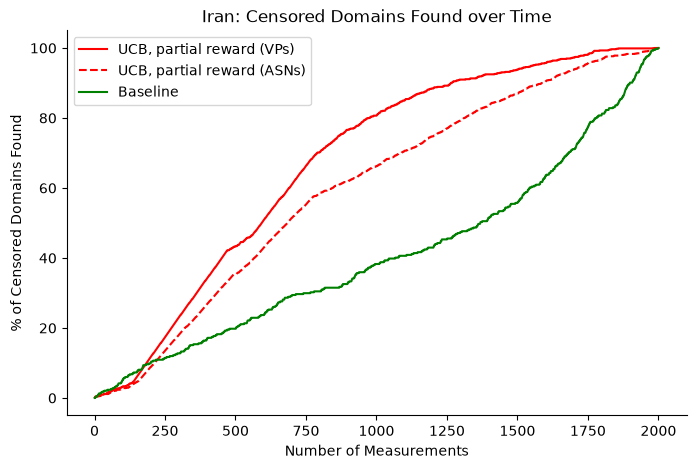

In [111]:
files = [
    # f"{DATA_DIR}/exp5/Iran.csv",
    f"{DATA_DIR}/exp6/Iran.csv",
    f"{DATA_DIR}/exp7/Iran.csv",
    f"{DATA_DIR}/baseline/Iran.csv"
]

runs, times, names, colors, lines = get_over_time_compare_data(files) 
print(len(runs))
# = list(map(load_run, files)
# times = list(map(lambda df: df["time"], runs))
# names = list(map(get_exeriment_name, files))

# runs = list(map(convert_to_percentage, map(cumulative_found, runs)))

# # Denominator: all censored domains found by EITHER run, so both curves
# # share one scale. Change this line if you want a different definition.
# total_censored = max(exp_found[-1], base_found[-1])

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

# ax.plot(exp["time"], 100 * exp_found / total_censored, label="exp6")
# ax.plot(base["time"], 100 * base_found / total_censored, label="baseline")
# ax.plot(exp["time"], 100 * exp_found / exp_found[-1], label="exp6")
# ax.plot(base["time"], 100 * base_found / base_found[-1], label="baseline")
ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Iran: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

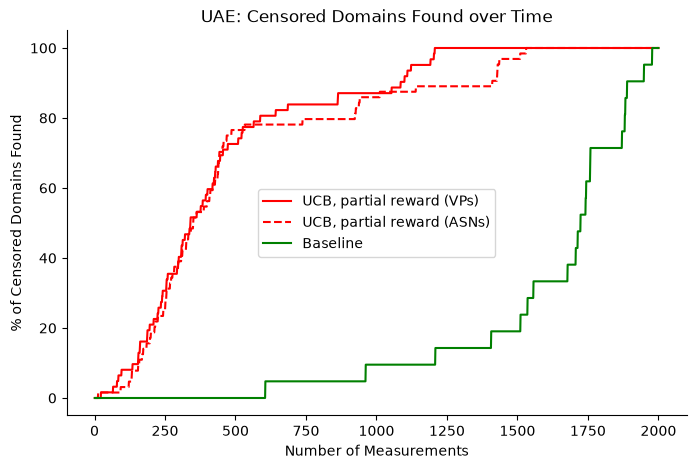

In [110]:
files = [
    # f"{DATA_DIR}/exp5/United_Arab_Emirates.csv",
    f"{DATA_DIR}/exp6/United_Arab_Emirates.csv",
    f"{DATA_DIR}/exp7/United_Arab_Emirates.csv",
    f"{DATA_DIR}/baseline/United_Arab_Emirates.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("UAE: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

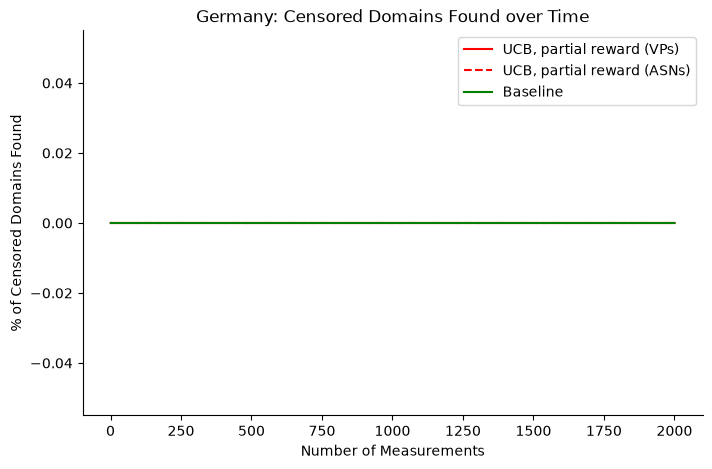

In [109]:
files = [
    # f"{DATA_DIR}/exp5/Germany.csv",
    f"{DATA_DIR}/exp6/Germany.csv",
    f"{DATA_DIR}/exp7/Germany.csv",
    f"{DATA_DIR}/baseline/Germany.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Germany: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

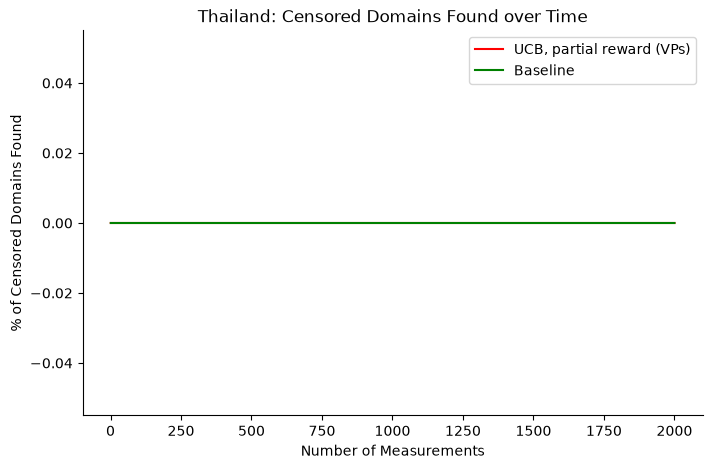

In [29]:
files = [
    # f"{DATA_DIR}/exp5/Thailand.csv",
    f"{DATA_DIR}/exp6/Thailand.csv",
    # f"{DATA_DIR}/exp7/Thailand.csv",
    f"{DATA_DIR}/baseline/Thailand.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Thailand: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

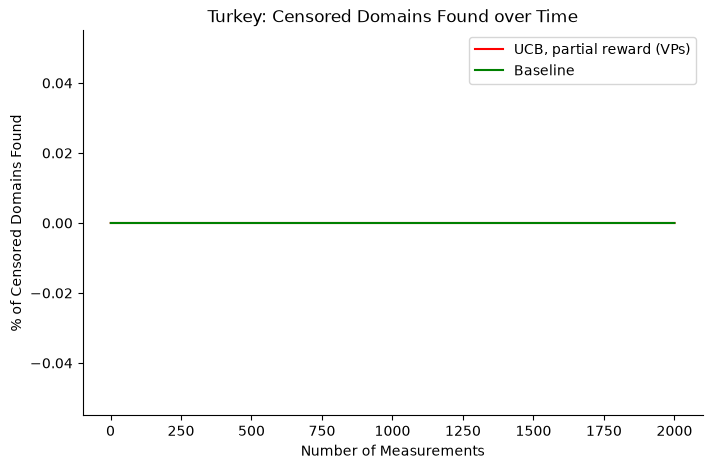

In [30]:
files = [
    # f"{DATA_DIR}/exp5/Turkey.csv",
    f"{DATA_DIR}/exp6/Turkey.csv",
    # f"{DATA_DIR}/exp7/Turkey.csv",
    f"{DATA_DIR}/baseline/Turkey.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Turkey: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

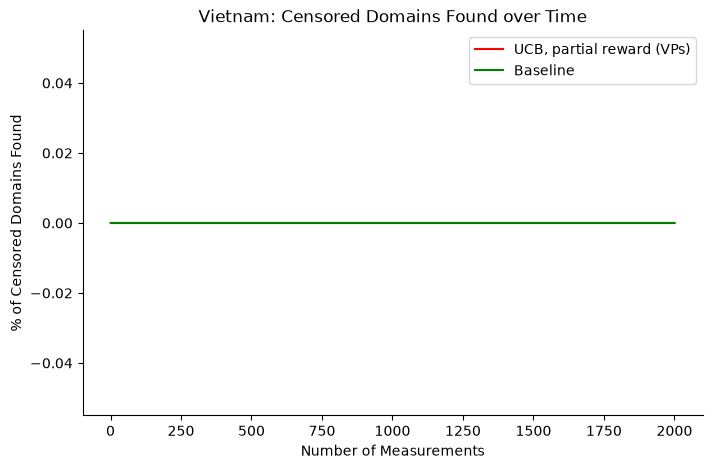

In [31]:
files = [
    # f"{DATA_DIR}/exp5/Vietnam.csv",
    f"{DATA_DIR}/exp6/Vietnam.csv",
    # f"{DATA_DIR}/exp7/Vietnam.csv",
    f"{DATA_DIR}/baseline/Vietnam.csv"
]
runs, times, names, colors, lines = get_over_time_compare_data(files) 

fig, ax = plt.subplots(figsize=(8, 5))
for _ in range(len(runs)):
    ax.plot(times[_], runs[_], label=names[_], color=colors[_], linestyle=lines[_])

ax.set_xlabel("Number of Measurements")
if USE_PERCENTAGES:
    ax.set_ylabel("% of Censored Domains Found")
else:
    ax.set_ylabel("Num Censored Domains Found")
ax.set_title("Vietnam: Censored Domains Found over Time")
ax.spines[["top", "right"]].set_visible(False)  # matches the reference style
ax.legend()
plt.show()

### All (sanity check)

## Box-whisker plot of arm pulls

In [115]:
def get_categories_to_plot(runs, min_domains, num_each):
    runs = map(load_run, runs)
    
    all_measured_domains = pd.concat(runs).drop_duplicates(subset="targets")
    filtered_domains = all_measured_domains.groupby("category").agg(
        n_domains=("targets", "nunique"),
        avg_reward=("rewards", "mean"),
    )
    filtered_domains = filtered_domains[filtered_domains["n_domains"] >= min_domains]
    filtered_domains = filtered_domains.sort_values("avg_reward", ascending=False)
    print(filtered_domains)

    top = list(filtered_domains.index[:num_each])
    bottom = list(filtered_domains.index[-num_each:])
    # dict.fromkeys drops repeats but keeps the order
    selected = list(dict.fromkeys(top + bottom))

    return selected

In [116]:
def get_scatter_plot_data(files, categories):
    runs = map(load_run, files)
    all_categories_per_run = [
        {cat: run[run["category"] == cat] for cat in categories}
        for run in runs
    ]
    category_rewards_per_run = [
        {cat: subs[cat]["rewards"].mean() for cat in categories}
        for subs in all_categories_per_run
    ]
    
    names = list(map(get_experiment_name, files))
    colors = list(map(get_experiment_color, files))
    
    return list(all_categories_per_run), list(category_rewards_per_run), names, colors

In [130]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

def plot_scatter_boxes(files, min_domains, n_each, country):
    # pop, readd is to avoid including baseline in get_categories_to_plot
    # Don't include baseline when calculating what categories to plot,
    # since we want to pick the most interesting categories reward-wise
    # and baseline doesn't try to pick "interesting" categories
    baseline, baseline_idx = None, None
    baseline_matches = [_ for _ in files if "baseline" in files]
    if baseline_matches:
        baseline_idx = files.index(baseline_matches)
        baseline = files.pop()
    categories = get_categories_to_plot(files, min_domains, n_each)
    if baseline_matches:
        files.append(baseline)
    
    all_categories, category_rewards, names, colors = get_scatter_plot_data(files, categories)
    
    X_AXIS_OFFSET_SCALE = 1
    BETWEEN_BOX_OFFSET_SCALE = 0.3
    PLOT_LENGTH_SCALE = 0.5
    BOX_WIDTH = 0.2
    
    def box_x(i, offset):
        return X_AXIS_OFFSET_SCALE * i + offset * BETWEEN_BOX_OFFSET_SCALE
    
    # plot length should be dependent on # categories and # runs
    num_categories = len(categories)
    num_runs = len(files)
    
    # fig, ax = plt.subplots(figsize=(num_categories * num_runs * PLOT_LENGTH_SCALE, 6))
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # need a list of idx, run subsets, rewards, names, colors
    # run subsets are the measurements that match each category for every category, so actually a 
    
    all_categories, category_rewards, names, colors = get_scatter_plot_data(files, categories)
    
    for i, cat in enumerate(categories):
        for offset, subs, color in zip(range(len(all_categories)), all_categories, colors):
            data = subs[cat]["time"].to_numpy()
            bp = ax.boxplot([data], 
                            positions=[box_x(i, offset)], 
                            widths=BOX_WIDTH,
                            patch_artist=True, showfliers=False,
                            medianprops={"color": "black"})
            bp["boxes"][0].set_facecolor(color)
            bp["boxes"][0].set_alpha(0.4)   # make the box semi-transparent
    
    rng = np.random.default_rng(0)  # fixed seed -> same jitter every run
    
    JITTER_HALF_LENGTH = BOX_WIDTH / 3
    for i, cat in enumerate(categories):
        for offset, subs in zip(range(len(all_categories)), all_categories):
            pts = subs[cat]
            # spread points sideways around the box center (box half-width is 0.5)
            x = box_x(i, offset) + rng.uniform(-JITTER_HALF_LENGTH, JITTER_HALF_LENGTH, size=len(pts))
            point_colors = np.where(pts["is_blocked"] == 1, "crimson", "gray")
            ax.scatter(x, pts["time"], c=point_colors, s=6, alpha=0.5, zorder=3)
    
    labels = []
    # iterate over cat, then run
    for cat in categories:
        label = cat
        for name, reward in zip(names, category_rewards):
            label = f"{label}\n{name}:{reward[cat]:.2f}"
        labels.append(label)
    
    ax.set_xticks([box_x(i, (num_runs - 1) / 2) for i in range(len(categories))])
    ax.set_xticklabels(labels, fontsize=8)
    
    ax.set_ylabel("Measurement Step")
    ax.set_title(f"{country}: When Each Category Was Tried", pad=22)
    
    # categories before this index are the "top" group, the rest are "bottom"
    split = num_categories // 2
    # halfway between the last box of the previous group and the first box of the next
    divider_x = (box_x(split - 1, num_runs - 1) + box_x(split, 0)) / 2
    ax.axvline(divider_x, color="black", linestyle="--", linewidth=1, alpha=0.5, zorder=0)
    
    # Below is code to add labels to each side on the top
    # can comment out and remove title padding if space needed
    # x-range covered by the boxes on each side of the divider
    left_center = (box_x(0, 0) + box_x(split - 1, num_runs - 1)) / 2
    right_center = (box_x(split, 0) + box_x(num_categories - 1, num_runs - 1)) / 2
    # x in data units, y in axes units (1.0 = top edge of the plot)
    xform = ax.get_xaxis_transform()
    ax.text(left_center, 1.0, "Most censored", transform=xform,
            ha="center", va="bottom", fontsize=10, fontweight="bold")
    ax.text(right_center, 1.0, "Less censored", transform=xform,
            ha="center", va="bottom", fontsize=10, fontweight="bold")
    
    handles = [Patch(color=color, label=name) for color, name in zip(colors, names)]
    handles.append(Line2D([0], [0], marker="o", color="w", markerfacecolor="crimson", label="blocked"))
    handles.append(Line2D([0], [0], marker="o", color="w", markerfacecolor="gray", label="not blocked"))
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.0, 1.2))
    ax.spines[["top", "right"]].set_visible(False)
    plt.show()

                        n_domains  avg_reward
category                                     
Pornography                   329    0.926322
Social Networks               239    0.797741
News & Media                  159    0.371069
Personal Blogs                114    0.286053
Ecommerce                     421    0.137696
Advertisements                132    0.125606
Information Technology        137    0.058394
Content Servers               292    0.044521
Information Security          110    0.018182
Technology                    183    0.016831
Business                      198    0.015152


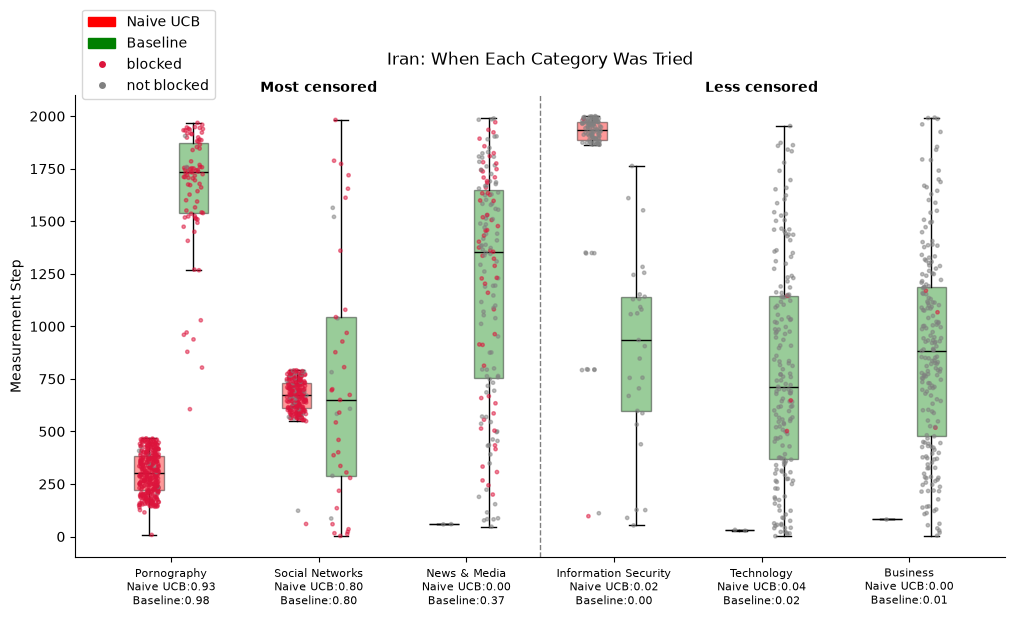

In [138]:
min_domains_Iran = 100   # category must have at least this many distinct domains
n_each_Iran = 3          # how many to take from the top and from the bottom

files_Iran = [
    f"{DATA_DIR}/exp1/Iran.csv",
    # f"{DATA_DIR}/exp3/Iran.csv",
    f"{DATA_DIR}/baseline/Iran.csv"
]

plot_scatter_boxes(files_Iran, min_domains_Iran, n_each_Iran, "Iran")

                      n_domains  avg_reward
category                                   
Pornography                 329    0.926322
Social Networks             239    0.797741
Video Streaming             394    0.347970
Personal Blogs              114    0.286053
Ecommerce                   421    0.137696
Advertisements              132    0.125606
Information Security        105    0.019048


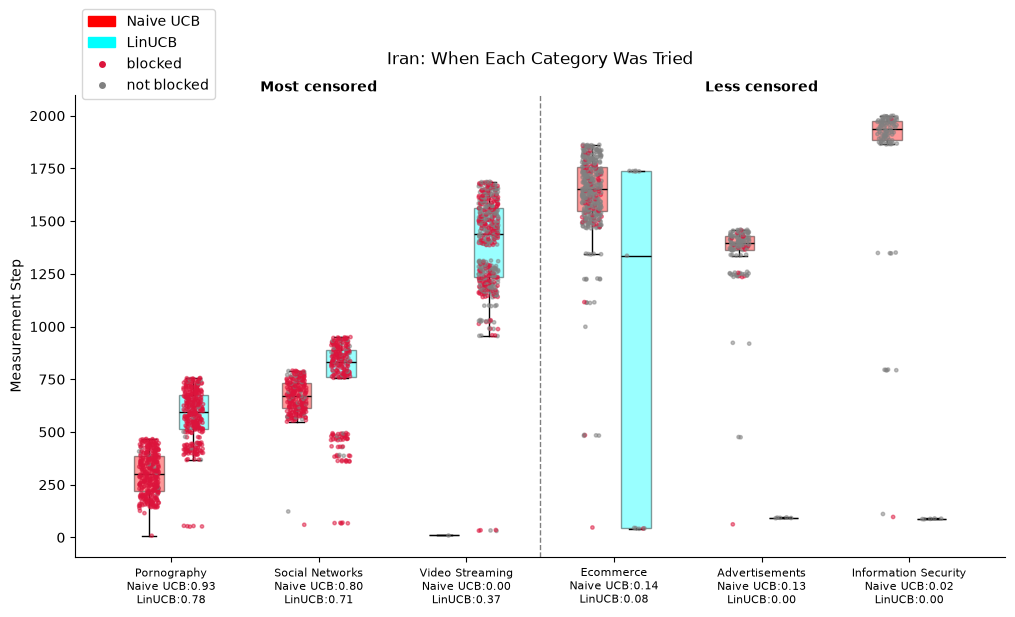

In [146]:
min_domains_Iran = 100   # category must have at least this many distinct domains
n_each_Iran = 3          # how many to take from the top and from the bottom

files_Iran = [
    f"{DATA_DIR}/exp1/Iran.csv",
    f"{DATA_DIR}/exp3/Iran.csv",
    # f"{DATA_DIR}/baseline/Iran.csv"
]

plot_scatter_boxes(files_Iran, min_domains_Iran, n_each_Iran, "Iran")

                      n_domains  avg_reward
category                                   
Pornography                 329    0.926322
Social Networks             239    0.797741
Video Streaming             391    0.376394
Personal Blogs              114    0.286053
Ecommerce                   421    0.137696
Advertisements              132    0.125606
Information Security        103    0.019417


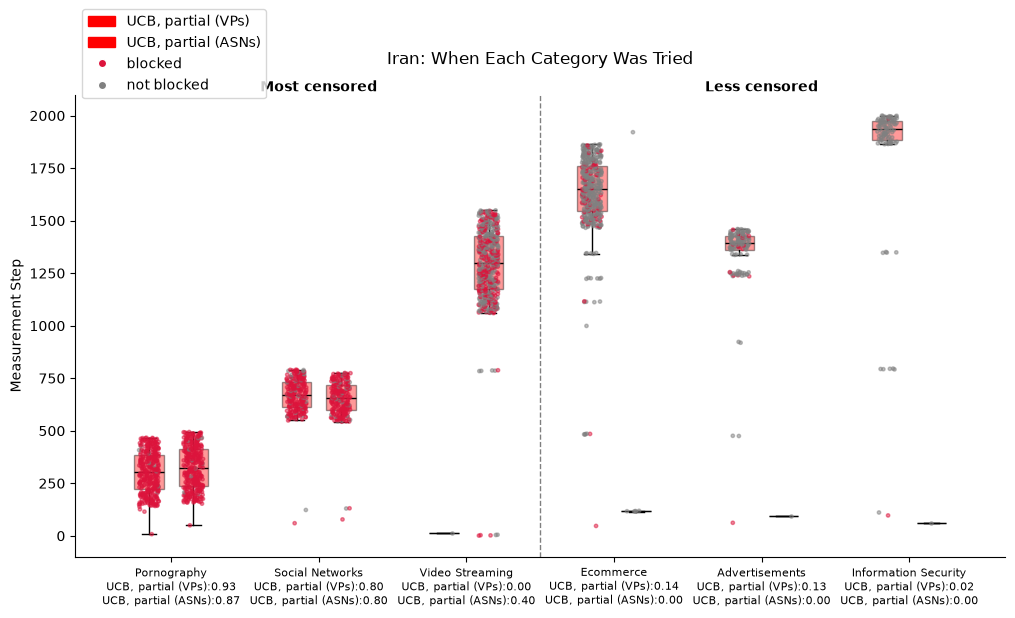

In [140]:
min_domains_Iran = 100   # category must have at least this many distinct domains
n_each_Iran = 3          # how many to take from the top and from the bottom

files_Iran = [
    f"{DATA_DIR}/exp6/Iran.csv",
    f"{DATA_DIR}/exp7/Iran.csv",
    # f"{DATA_DIR}/baseline/Iran.csv"
]

plot_scatter_boxes(files_Iran, min_domains_Iran, n_each_Iran, "Iran")

### China

                        n_domains  avg_reward
category                                     
Video Streaming               535    0.211252
News & Media                  111    0.126126
Pornography                   326    0.073865
Information Technology        134    0.022687
Technology                    635    0.017496
Business                      185    0.005405
Content Servers               292    0.000000


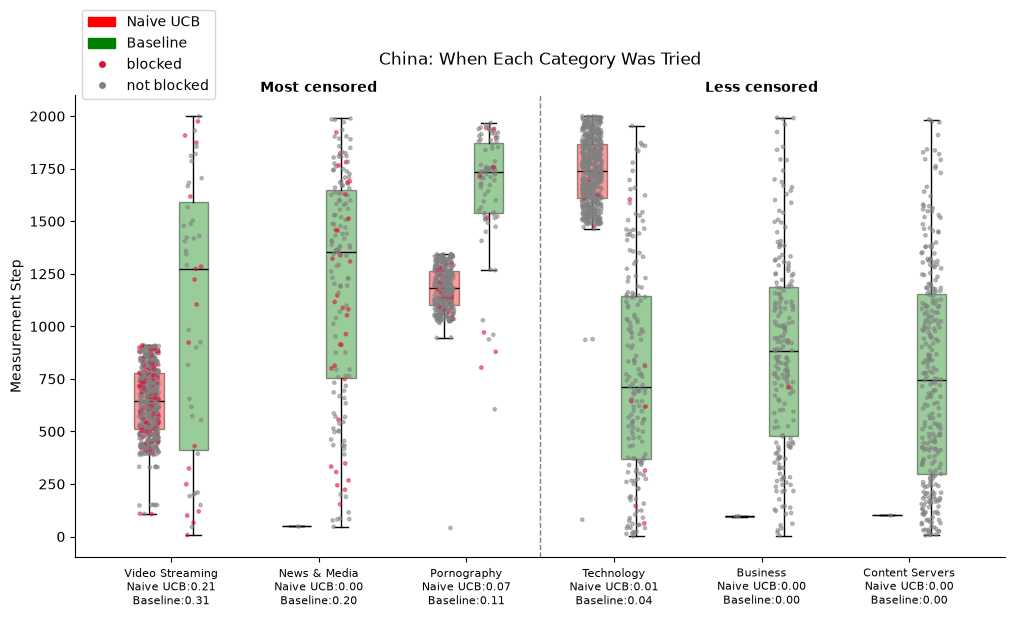

In [141]:
min_domains_China = 100   # category must have at least this many distinct domains
n_each_China = 3          # how many to take from the top and from the bottom

files_China = [
    f"{DATA_DIR}/exp1/China.csv",
    # f"{DATA_DIR}/exp3/China.csv",
    f"{DATA_DIR}/baseline/China.csv"
]

plot_scatter_boxes(files_China, min_domains_China, n_each_China, "China")

                 n_domains  avg_reward
category                              
Video Streaming        535    0.211252
News & Media           110    0.109091
Pornography            326    0.073865
Technology             525    0.009733


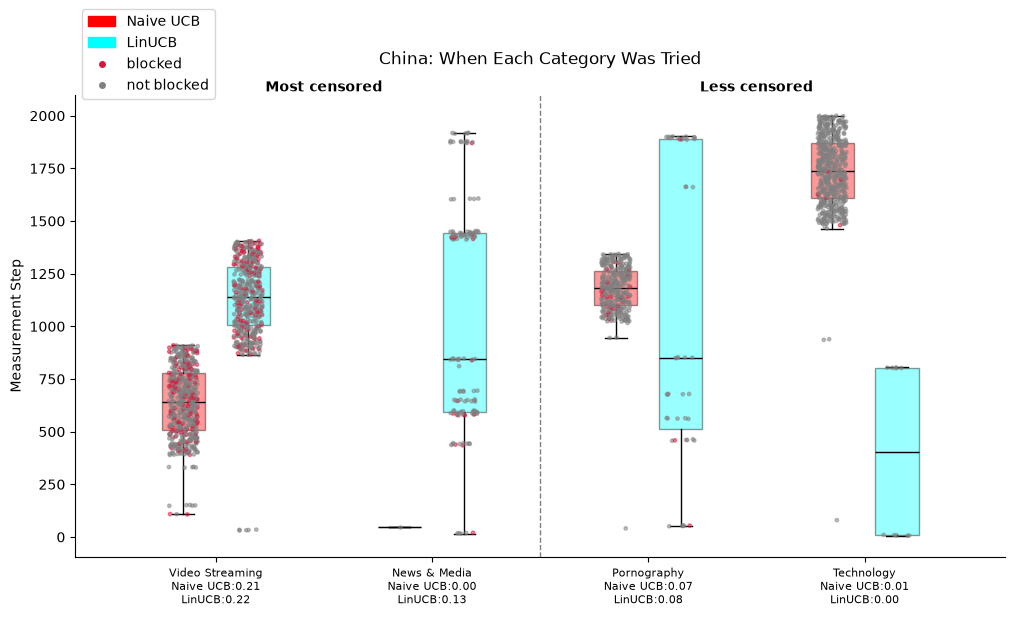

In [142]:
min_domains_China = 100   # category must have at least this many distinct domains
n_each_China = 3          # how many to take from the top and from the bottom

files_China = [
    f"{DATA_DIR}/exp1/China.csv",
    f"{DATA_DIR}/exp3/China.csv",
    # f"{DATA_DIR}/baseline/China.csv"
]

plot_scatter_boxes(files_China, min_domains_China, n_each_China, "China")

                 n_domains  avg_reward
category                              
Video Streaming        535    0.211252
News & Media           623    0.127127
Pornography            326    0.073865
Social Networks        146    0.056164
Technology             522    0.009789


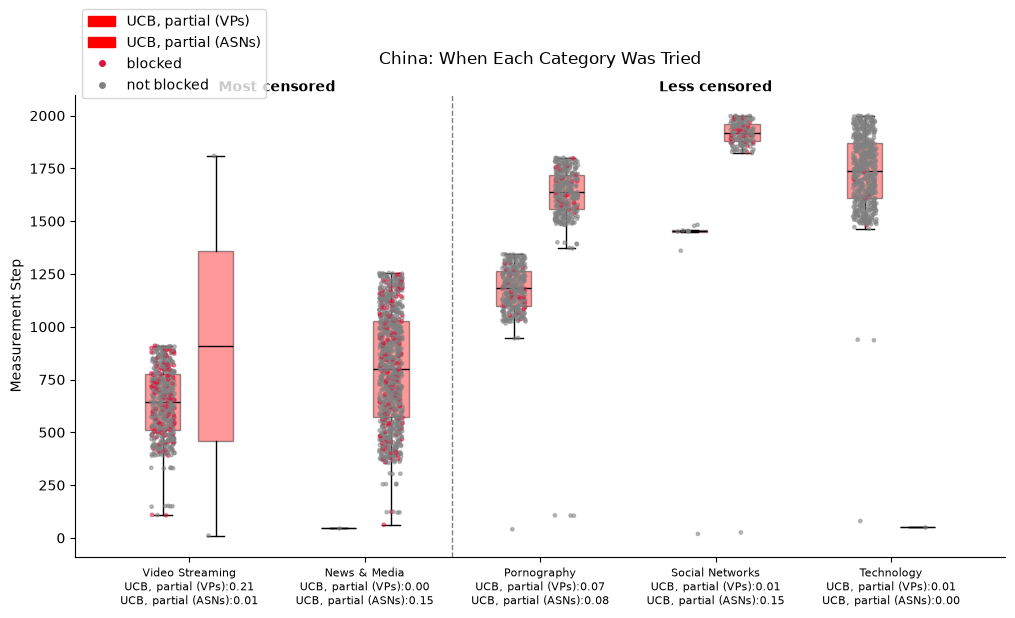

In [143]:
min_domains_China = 100   # category must have at least this many distinct domains
n_each_China = 3          # how many to take from the top and from the bottom

files_China = [
    f"{DATA_DIR}/exp6/China.csv",
    f"{DATA_DIR}/exp7/China.csv",
    # f"{DATA_DIR}/baseline/China.csv"
]

plot_scatter_boxes(files_China, min_domains_China, n_each_China, "China")

### UAE

I expect this to look the most interesting when comparing majority vs partial votes?

                 n_domains  avg_reward
category                              
Pornography            327    0.259878
Social Networks        198    0.026818
Sports                 129    0.010388
Advertisements         127    0.008268
Search Engines         348    0.007241
Education              427    0.003794


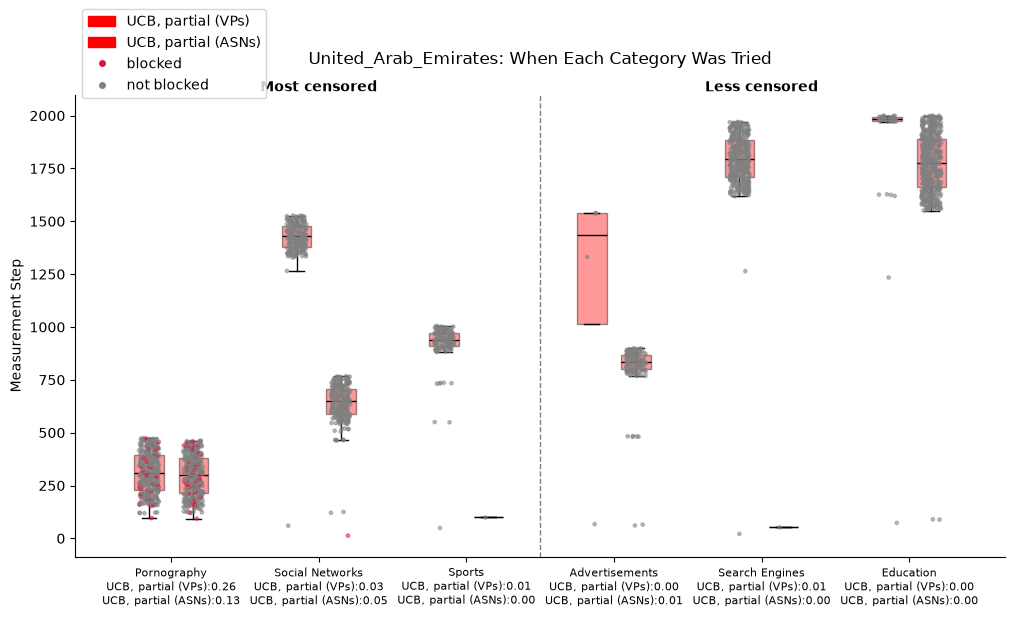

In [144]:
min_domains_UAE = 100   # category must have at least this many distinct domains
n_each_UAE = 3          # how many to take from the top and from the bottom

files_UAE = [
    f"{DATA_DIR}/exp6/United_Arab_Emirates.csv",
    f"{DATA_DIR}/exp7/United_Arab_Emirates.csv",
    # f"{DATA_DIR}/baseline/China.csv"
]

plot_scatter_boxes(files_UAE, min_domains_UAE, n_each_UAE, "United_Arab_Emirates")

In [35]:
# all_categories, category_rewards, names, colors = get_scatter_plot_data(files, categories)

# print(len(all_categories), names)                        # one entry per run?
# for subs in all_categories:
#     print({c: len(subs[c]) for c in categories})         # rows per category
# print(all_categories[0][categories[0]].columns.tolist()) # expected column names?

2 ['Naive UCB', 'Baseline']
{'Pornography': 329, 'Social Networks': 239, 'Movies': 84, 'Advertisements': 132, 'Information Security': 103, 'No Content': 60}
{'Pornography': 83, 'Social Networks': 41, 'Movies': 23, 'Advertisements': 35, 'Information Security': 29, 'No Content': 1}
['episode', 'time', 'action', 'targets', 'rewards', 'q_value', 'is_blocked', 'is_optimal', 'coverage', 'category']


In [36]:
# exp_sub = {cat: exp[exp["category"] == cat] for cat in selected}
# base_sub = {cat: base[base["category"] == cat] for cat in selected}

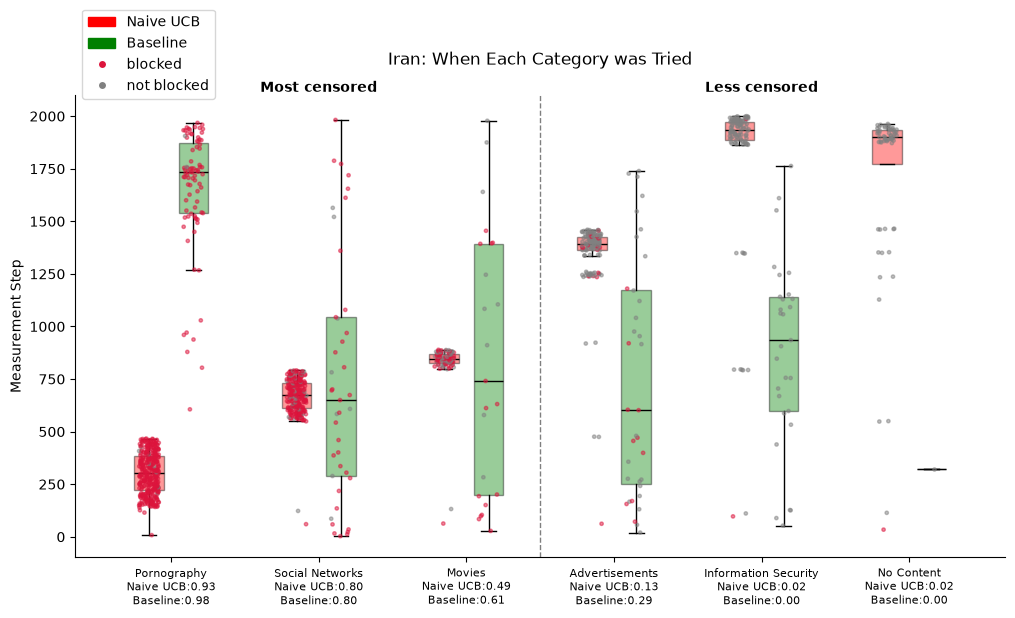

In [37]:
# from matplotlib.lines import Line2D
# from matplotlib.patches import Patch

# X_AXIS_OFFSET_SCALE = 1
# BETWEEN_BOX_OFFSET_SCALE = 0.3
# PLOT_LENGTH_SCALE = 0.5
# BOX_WIDTH = 0.2

# def box_x(i, offset):
#     return X_AXIS_OFFSET_SCALE * i + offset * BETWEEN_BOX_OFFSET_SCALE

# # plot length should be dependent on # categories and # runs
# num_categories = len(categories)
# num_runs = len(files)

# # fig, ax = plt.subplots(figsize=(num_categories * num_runs * PLOT_LENGTH_SCALE, 6))
# fig, ax = plt.subplots(figsize=(12, 6))

# # need a list of idx, run subsets, rewards, names, colors
# # run subsets are the measurements that match each category for every category, so actually a 

# all_categories, category_rewards, names, colors = get_scatter_plot_data(files, categories)

# for i, cat in enumerate(categories):
#     for offset, subs, color in zip(range(len(all_categories)), all_categories, colors):
#         data = subs[cat]["time"].to_numpy()
#         bp = ax.boxplot([data], 
#                         positions=[box_x(i, offset)], 
#                         widths=BOX_WIDTH,
#                         patch_artist=True, showfliers=False,
#                         medianprops={"color": "black"})
#         bp["boxes"][0].set_facecolor(color)
#         bp["boxes"][0].set_alpha(0.4)   # make the box semi-transparent

# rng = np.random.default_rng(0)  # fixed seed -> same jitter every run

# JITTER_HALF_LENGTH = BOX_WIDTH / 3
# for i, cat in enumerate(categories):
#     for offset, subs in zip(range(len(all_categories)), all_categories):
#         pts = subs[cat]
#         # spread points sideways around the box center (box half-width is 0.5)
#         x = box_x(i, offset) + rng.uniform(-JITTER_HALF_LENGTH, JITTER_HALF_LENGTH, size=len(pts))
#         point_colors = np.where(pts["is_blocked"] == 1, "crimson", "gray")
#         ax.scatter(x, pts["time"], c=point_colors, s=6, alpha=0.5, zorder=3)

# labels = []
# # iterate over cat, then run
# for cat in categories:
#     label = cat
#     for name, reward in zip(names, category_rewards):
#         label = f"{label}\n{name}:{reward[cat]:.2f}"
#     labels.append(label)

# ax.set_xticks([box_x(i, (num_runs - 1) / 2) for i in range(len(categories))])
# ax.set_xticklabels(labels, fontsize=8)

# ax.set_ylabel("Measurement Step")
# ax.set_title("Iran: When Each Category was Tried", pad=22)

# # categories before this index are the "top" group, the rest are "bottom"
# split = num_categories // 2
# # halfway between the last box of the previous group and the first box of the next
# divider_x = (box_x(split - 1, num_runs - 1) + box_x(split, 0)) / 2
# ax.axvline(divider_x, color="black", linestyle="--", linewidth=1, alpha=0.5, zorder=0)

# # Below is code to add labels to each side on the top
# # can comment out and remove title padding if space needed
# # x-range covered by the boxes on each side of the divider
# left_center = (box_x(0, 0) + box_x(split - 1, num_runs - 1)) / 2
# right_center = (box_x(split, 0) + box_x(num_categories - 1, num_runs - 1)) / 2
# # x in data units, y in axes units (1.0 = top edge of the plot)
# xform = ax.get_xaxis_transform()
# ax.text(left_center, 1.0, "Most censored", transform=xform,
#         ha="center", va="bottom", fontsize=10, fontweight="bold")
# ax.text(right_center, 1.0, "Less censored", transform=xform,
#         ha="center", va="bottom", fontsize=10, fontweight="bold")

# handles = [Patch(color=color, label=name) for color, name in zip(colors, names)]
# handles.append(Line2D([0], [0], marker="o", color="w", markerfacecolor="crimson", label="blocked"))
# handles.append(Line2D([0], [0], marker="o", color="w", markerfacecolor="gray", label="not blocked"))
# ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.0, 1.2))
# ax.spines[["top", "right"]].set_visible(False)
# plt.show()

## Heat map

In [55]:
# this looks a little different because I made Claude do this without
# the context from the rest of the notebook
TOP_N = 20

countries = ["China", "Germany", "Iran", "Thailand", "Turkey",
             "United Arab Emirates", "Vietnam"]

In [56]:
def count_by_category(column_files):
    blocked, tested = {}, {}
    for label, path in column_files.items():
        grouped = load_run(path).groupby("category")["is_blocked"]
        blocked[label] = grouped.sum()    # how many measurements were blocked
        tested[label] = grouped.count()   # how many measurements were made
    # one row per category, one column per label; 0 where a category was never tried
    blocked = pd.DataFrame(blocked).fillna(0).astype(int)
    tested = pd.DataFrame(tested).fillna(0).astype(int)
    return blocked, tested

In [63]:
def plot_heatmap(column_files, exp_name):
    blocked, tested = count_by_category(column_files)
    
    # rank categories by total blocked measurements across ALL columns
    top_categories = blocked.sum(axis=1).nlargest(TOP_N).index
    
    # ends up being ordered by count of blocked domains across all countries
    # call sort_index() on each of these to sort alphabetically instead
    blocked_top = blocked.loc[top_categories]
    tested_top = tested.loc[top_categories]
    
    # block rate; NaN (not 0%) where nothing was tested, so those cells stay distinguishable
    rate = blocked_top / tested_top.replace(0, np.nan)

    fig, ax = plt.subplots(figsize=(11, 9))

    cmap = plt.get_cmap("YlOrRd").copy()
    cmap.set_bad("lightgray")   # untested cells show as gray
    
    im = ax.imshow(np.ma.masked_invalid(rate.to_numpy()),
                   cmap=cmap, vmin=0, vmax=1, aspect="auto")
    
    # axis labels come straight from the table, so any new columns appear automatically
    ax.set_xticks(range(rate.shape[1]))
    ax.set_xticklabels(rate.columns, rotation=30, ha="right")
    ax.set_yticks(range(rate.shape[0]))
    ax.set_yticklabels(rate.index)
    
    # thin white lines between cells (minor ticks sit on the cell borders)
    ax.set_xticks(np.arange(-0.5, rate.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, rate.shape[0], 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1)
    ax.tick_params(which="minor", length=0)
    
    for r in range(rate.shape[0]):
        for c in range(rate.shape[1]):
            b = blocked_top.iat[r, c]
            t = tested_top.iat[r, c]
            value = rate.iat[r, c]
    
            pct = "n/a" if np.isnan(value) else f"{value:.0%}"
            color = "white" if value > 0.6 else "black"   # readable on dark cells
    
            ax.text(c, r, f"{b}/{t}\n({pct})",
                    ha="center", va="center", fontsize=7, color=color)
    
    cbar = fig.colorbar(im, ax=ax, shrink=0.6)
    cbar.set_label("Block Rate")
    
    ax.set_title(f"Blocking Rate by Category × Country, {exp_name}", fontweight="bold")
    plt.tight_layout()
    plt.show()

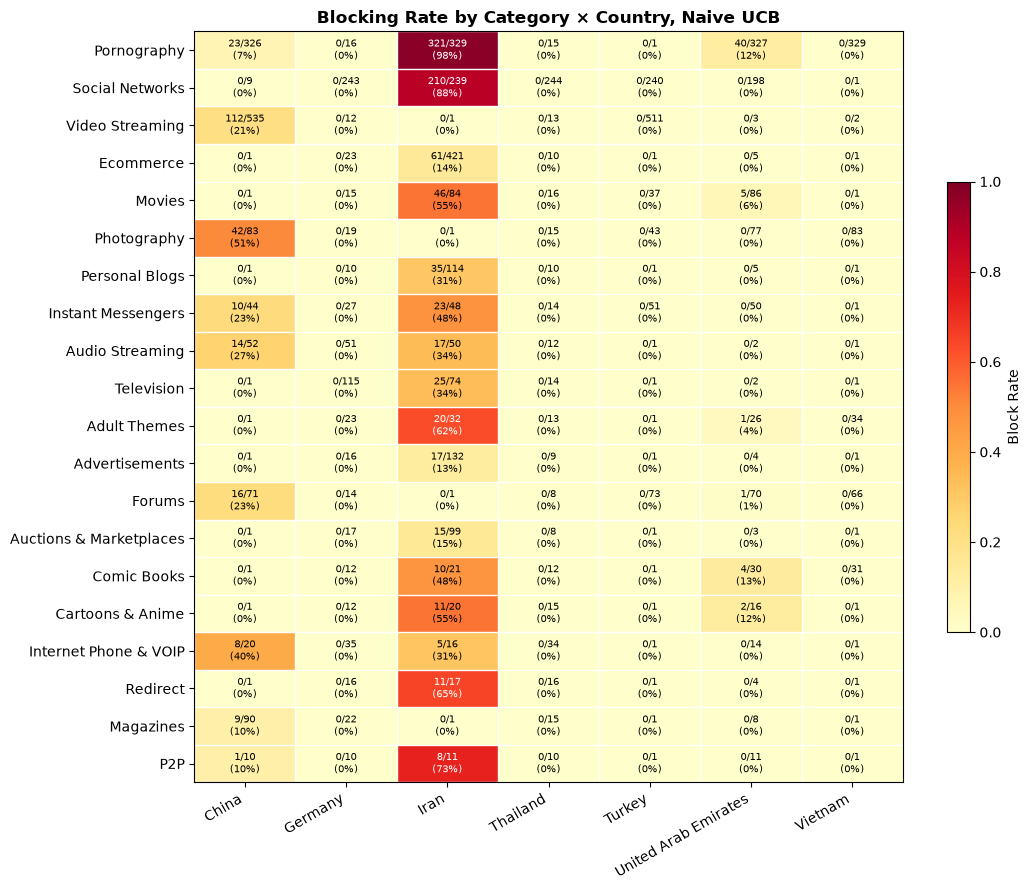

In [64]:
# {column label -> CSV file}. Each entry becomes one column in the heatmap.
column_files_exp1 = {c: f"{DATA_DIR}/exp1/{c.replace(' ', '_')}.csv" for c in countries}
plot_heatmap(column_files_exp1, "Naive UCB")

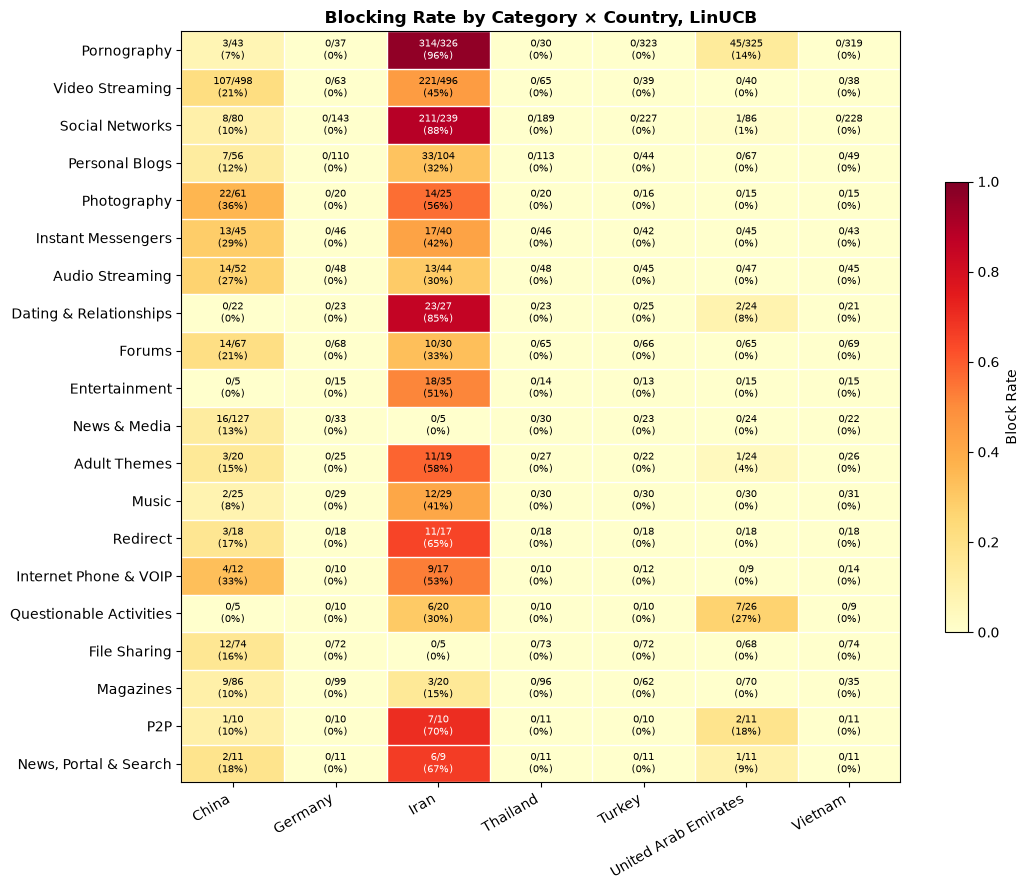

In [65]:
# {column label -> CSV file}. Each entry becomes one column in the heatmap.
column_files_exp3 = {c: f"{DATA_DIR}/exp3/{c.replace(' ', '_')}.csv" for c in countries}
plot_heatmap(column_files_exp3, "LinUCB")

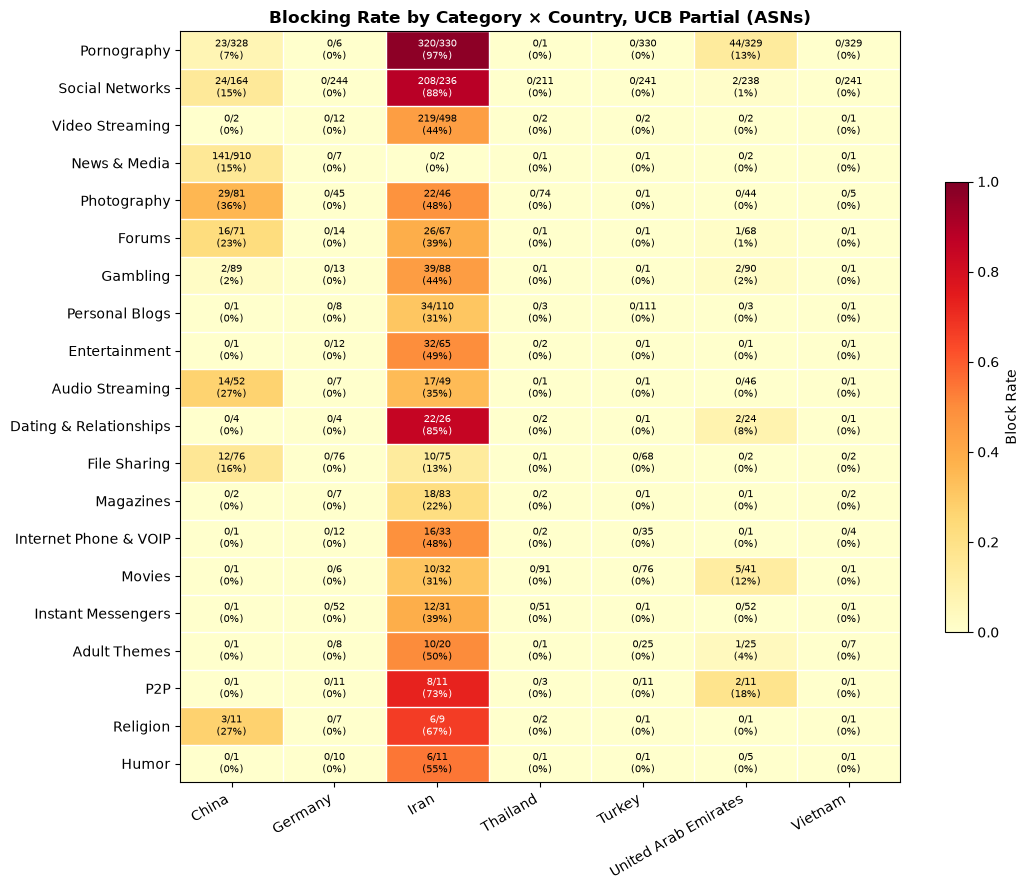

In [151]:
# {column label -> CSV file}. Each entry becomes one column in the heatmap.
column_files_exp7 = {c: f"{DATA_DIR}/exp7/{c.replace(' ', '_')}.csv" for c in countries}
plot_heatmap(column_files_exp7, "UCB Partial (ASNs)")

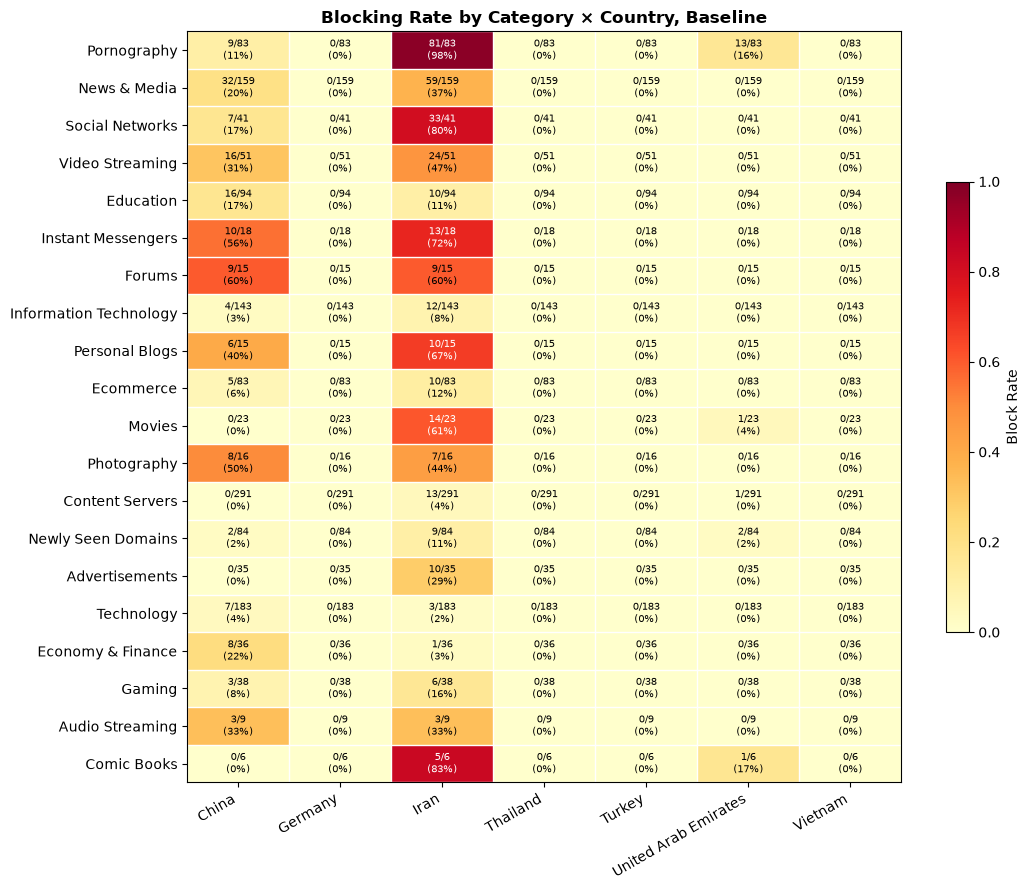

In [152]:
# {column label -> CSV file}. Each entry becomes one column in the heatmap.
column_files_baseline = {c: f"{DATA_DIR}/baseline/{c.replace(' ', '_')}.csv" for c in countries}
plot_heatmap(column_files_baseline, "Baseline")

## Arm selection over time

In [39]:
NUM_ARMS_TO_COMPARE = 10

exp = load_run(f"{DATA_DIR}/exp1/Iran.csv")

top_arms = exp["category"].value_counts().head(NUM_ARMS_TO_COMPARE).index
print(list(top_arms))  # check which categories were picked

['Ecommerce', 'Pornography', 'Social Networks', 'Advertisements', 'Personal Blogs', 'Information Security', 'Auctions & Marketplaces', 'Movies', 'Television', 'No Content']


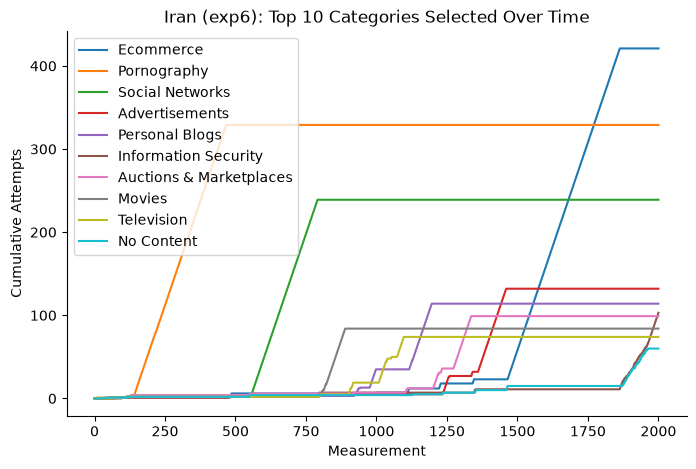

In [40]:
fig, ax = plt.subplots(figsize=(8, 5))
for cat in top_arms:
    # True/False per measurement -> running total of times this arm was picked
    ax.plot(exp["time"], (exp["category"] == cat).cumsum(), label=cat)

ax.set_xlabel("Measurement")
ax.set_ylabel("Cumulative Attempts")
ax.set_title(f"Iran (exp6): Top {NUM_ARMS_TO_COMPARE} Categories Selected Over Time")
ax.spines[["top", "right"]].set_visible(False)
ax.legend()
plt.show()